# Lab 5 적용 — 파이프라인 · 앙상블 · 튜닝 · 모델 저장 (Give Me Some Credit)

**Lab 4에서 넘어온 질문:** 지금까지 로그+표준화를 *전체 데이터에 먼저* 맞추고 교차검증했다(누수). 이것을 바로잡아도 결과가 같을까?
그리고 앙상블과 튜닝으로 더 올릴 수 있을까?

Lab 5의 순서를 그대로 따른다.
1. Pipeline: 전처리를 각 fold의 학습 데이터 안에서만 맞추기 → FeatureUnion
2. 앙상블: Bagging(결정트리 100개) → Random Forest(100개, 변수 3개) → AdaBoost(30개) → Voting
3. 튜닝: Grid Search → Random Search
4. 모델 저장: pickle / joblib

여기에 Lab 1에서 찾고 처리하지 않았던 **문제 데이터 정리**(late30의 96/98 코드, 소득 대체값 6638/6746)를 파이프라인 단계로 추가한다.
평가는 계속 **층화 10-fold AUC**, Lab 4 결론대로 로지스틱 회귀는 **연체자 가중치(balanced)**를 쓴다.

In [1]:
import glob, os, time, sys
import numpy, sklearn
from pandas import read_csv, DataFrame
from matplotlib import pyplot, font_manager
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

for p in glob.glob(os.path.expandvars(r'%LOCALAPPDATA%\Microsoft\Windows\Fonts\Pretendard-*.ttf')):
    font_manager.fontManager.addfont(p)
pyplot.rcParams['font.family'] = 'Pretendard'
pyplot.rcParams['axes.unicode_minus'] = False
BLUE, RED, GRAY, VIOLET, INK = '#3182F6', '#F04452', '#B0B8C1', '#7C5CFF', '#191F28'

filename = '../data/givemesomecredit.csv'
names = ['target', 'revol', 'age', 'late30', 'debt', 'income', 'depend', 'defaulted', 'loans']
features = names[1:]
dataframe = read_csv(filename, names=names, header=0)
array = dataframe.values
X = array[:, 1:9].astype(float)     # 이번에는 원본 그대로 넣고, 변환은 파이프라인 안에서 한다
Y = array[:, 0].astype(int)
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)
LOGC = [features.index(c) for c in ['revol', 'late30', 'debt', 'income']]

def log4(A):
    """치우친 4개 열에 log1p (Lab 2 결론). 값마다 따로 계산하므로 학습 데이터 정보를 쓰지 않는다."""
    A = A.copy(); A[:, LOGC] = numpy.log1p(A[:, LOGC]); return A

def clean(A):
    """Lab 1에서 찾은 문제 데이터 정리: late30의 96/98 코드는 0으로 바꾸고 표시 열 추가, 소득 대체값(6638/6746) 표시 열 추가."""
    A = A.copy()
    code = numpy.isin(A[:, 2], [96, 98]).astype(float)
    fill = numpy.isin(A[:, 4], [6638, 6746]).astype(float)
    A[code == 1, 2] = 0
    return numpy.column_stack([A, code, fill])

def auc(model, XX=X):
    t0 = time.time()
    r = cross_val_score(model, XX, Y, cv=kfold, scoring='roc_auc', n_jobs=-1)
    return r, time.time() - t0
print(X.shape)

(150000, 8)


## 0. 정리할 데이터 다시 보기 (Lab 1의 발견)

In [2]:
code96 = numpy.isin(X[:, 2], [96, 98]); fill = numpy.isin(X[:, 4], [6638, 6746])
print(f'late30 = 96/98: {code96.sum()}행, 연체율 {Y[code96].mean():.1%} (전체 {Y.mean():.1%})')
print(f'  그중 연체 이력(defaulted)=1: {(X[code96, 6] == 1).mean():.1%}')
print(f'소득 = 6638/6746: {fill.sum():,}행, 연체율 {Y[fill].mean():.1%} (나머지 {Y[~fill].mean():.1%})')

late30 = 96/98: 269행, 연체율 54.6% (전체 6.7%)
  그중 연체 이력(defaulted)=1: 100.0%
소득 = 6638/6746: 29,737행, 연체율 5.6% (나머지 6.9%)


## 1. Pipeline — 누수 막기 (Lab 5: `Pipeline([('standardize', StandardScaler()), ('lda', LDA())])`)

In [3]:
Xleak = StandardScaler().fit_transform(log4(X))       # Lab 2~4 방식: 전체에 먼저 맞춤 (누수)
lr = lambda: LogisticRegression(solver='liblinear', class_weight='balanced')
rows = []
for name, leak_model, pipe in [
        ('LR 가중치', lr(), Pipeline([('log', FunctionTransformer(log4)), ('standardize', StandardScaler()), ('lr', lr())])),
        ('LDA', LinearDiscriminantAnalysis(), Pipeline([('log', FunctionTransformer(log4)), ('standardize', StandardScaler()), ('lda', LinearDiscriminantAnalysis())]))]:
    r1, _ = auc(leak_model, Xleak)
    r2, _ = auc(pipe)
    rows.append((name, r1.mean(), r2.mean(), r2.std()))
    print(f'{name}: 전체에 먼저 맞춤 {r1.mean():.5f}  →  파이프라인 {r2.mean():.5f} ({r2.std():.4f})')

LR 가중치: 전체에 먼저 맞춤 0.84358  →  파이프라인 0.84358 (0.0073)


LDA: 전체에 먼저 맞춤 0.83176  →  파이프라인 0.83176 (0.0082)


In [4]:
# 왜 같을까? fold마다 표준화에 쓰는 평균이 얼마나 달라지는지 확인
means = numpy.array([log4(X[tr]).mean(axis=0) for tr, _ in kfold.split(X, Y)])
stds = log4(X).std(axis=0)
print('fold 간 평균 차이 / 전체 표준편차 (최대):', (means.std(axis=0) / stds).max().round(5))

fold 간 평균 차이 / 전체 표준편차 (최대): 0.00098


### 1-2. 데이터 정리를 파이프라인에 추가

In [5]:
clean_rows = {}
for name, est in [('LR 가중치', lr()), ('LDA', LinearDiscriminantAnalysis())]:
    base = Pipeline([('log', FunctionTransformer(log4)), ('standardize', StandardScaler()), ('m', est)])
    cl = Pipeline([('clean', FunctionTransformer(clean)), ('log', FunctionTransformer(log4)), ('standardize', StandardScaler()), ('m', est)])
    r1, _ = auc(base); r2, _ = auc(cl)
    clean_rows[name] = (r1, r2)
    print(f'{name}: 정리 전 {r1.mean():.5f} → 정리 후 {r2.mean():.5f}')

LR 가중치: 정리 전 0.84358 → 정리 후 0.84356


LDA: 정리 전 0.83176 → 정리 후 0.83250


### 1-3. FeatureUnion (Lab 5: PCA 3개 + SelectKBest 6개를 합쳐 로지스틱 회귀)

In [6]:
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest
feature_union = FeatureUnion([('pca', PCA(n_components=3)), ('select_best', SelectKBest(k=6))])
model = Pipeline([('log', FunctionTransformer(log4)), ('standardize', StandardScaler()),
                  ('feature_union', feature_union), ('logistic', lr())])
r, sec = auc(model)
print(f'FeatureUnion + LR: {r.mean():.5f} ({r.std():.4f})')

FeatureUnion + LR: 0.84358 (0.0073)


## 2. 앙상블 (트리 계열은 변환이 필요 없어 원본 그대로)

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, VotingClassifier
seed = 7
lr_pipe = Pipeline([('log', FunctionTransformer(log4)), ('standardize', StandardScaler()), ('lr', lr())])
ensembles = [
    ('결정트리 1개', DecisionTreeClassifier(random_state=seed)),
    ('Bagging 100', BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, random_state=seed, n_jobs=-1)),
    ('RF 100', RandomForestClassifier(n_estimators=100, max_features=3, random_state=seed, n_jobs=-1)),
    ('AdaBoost 30', AdaBoostClassifier(n_estimators=30, random_state=seed)),
    ('Voting', VotingClassifier([('logistic', lr_pipe), ('cart', DecisionTreeClassifier(random_state=seed)), ('nb', GaussianNB())], voting='soft')),
]
ens = {}
for name, m in ensembles:
    r, sec = auc(m)
    ens[name] = (r, sec)
    print(f'{name}: AUC {r.mean():.4f} ({r.std():.4f}) · {sec:.0f}초')

결정트리 1개: AUC 0.5970 (0.0049) · 3초


Bagging 100: AUC 0.8186 (0.0081) · 124초


RF 100: AUC 0.8244 (0.0059) · 91초


AdaBoost 30: AUC 0.8471 (0.0069) · 18초


Voting: AUC 0.8301 (0.0077) · 8초


**(k)(l) 앙상블 해석:** 결정트리 1개(0.595)는 여러 개를 합치자 크게 올랐다(Bagging 0.819, RF 0.824). 서로 다른 데이터로 만든 트리의 실수가 평균으로 상쇄되기 때문이다.
그래도 각 트리가 끝까지 자라 학습 데이터를 외우는 문제는 남아 있어 LR 가중치(0.844)보다 낮다.
AdaBoost는 얕은 트리(깊이 1)를 30개 이어 붙여 앞 트리의 실수를 고치게 해 0.847로 가장 높았다.
Voting은 0.830으로 LR 하나보다 낮았다. 과적합된 결정트리의 확률이 평균을 끌어내렸다.
→ 더 볼 만한 것: **트리가 외우지 못하게 막은 RF**(잎의 최소 인원 제한)와 **AdaBoost**. 이것을 3. 튜닝에서 찾는다.

## 3. 튜닝 — Grid Search (Lab 5: `GridSearchCV`, 1차원 격자)
RF의 `min_samples_leaf`(잎 하나에 최소 몇 명이 남아야 하는지)를 격자로 찾는다. 클수록 트리가 덜 외운다.

In [8]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import randint
rf = RandomForestClassifier(n_estimators=100, max_features=3, random_state=seed, n_jobs=-1)
leaves = numpy.array([1, 10, 50, 100, 200])
t0 = time.time()
grid = GridSearchCV(estimator=rf, param_grid=dict(min_samples_leaf=leaves), scoring='roc_auc', cv=kfold)
grid.fit(X, Y)
grid_sec = time.time() - t0
for leaf, m, s in zip(leaves, grid.cv_results_['mean_test_score'], grid.cv_results_['std_test_score']):
    print(f'min_samples_leaf={leaf:>3}: AUC {m:.4f} ({s:.4f})')
print('best:', grid.best_params_, round(grid.best_score_, 4), f'· {grid_sec / 60:.1f}분')

min_samples_leaf=  1: AUC 0.8244 (0.0059)
min_samples_leaf= 10: AUC 0.8487 (0.0067)
min_samples_leaf= 50: AUC 0.8546 (0.0068)
min_samples_leaf=100: AUC 0.8550 (0.0068)
min_samples_leaf=200: AUC 0.8555 (0.0068)
best: {'min_samples_leaf': np.int64(200)} 0.8555 · 6.9분


## 3. 튜닝 — Random Search (Lab 5: `RandomizedSearchCV`, 1~300 사이 무작위 10번)

In [9]:
t0 = time.time()
rsearch = RandomizedSearchCV(estimator=rf, param_distributions={'min_samples_leaf': randint(1, 301)},
                             n_iter=10, scoring='roc_auc', cv=kfold, random_state=7)
rsearch.fit(X, Y)
rand_sec = time.time() - t0
tried = sorted(zip(rsearch.cv_results_['param_min_samples_leaf'], rsearch.cv_results_['mean_test_score']))
print('시도한 값:', [(int(a), round(b, 4)) for a, b in tried])
print('best:', rsearch.best_params_, round(rsearch.best_score_, 4), f'· {rand_sec / 60:.1f}분')

시도한 값: [(24, np.float64(0.8528)), (26, np.float64(0.8532)), (43, np.float64(0.8546)), (68, np.float64(0.855)), (73, np.float64(0.8552)), (104, np.float64(0.8555)), (176, np.float64(0.8555)), (186, np.float64(0.8555)), (197, np.float64(0.8554)), (212, np.float64(0.8555))]
best: {'min_samples_leaf': 176} 0.8555 · 11.5분


In [10]:
# 로지스틱 회귀의 규제 강도 C도 격자로 확인
lr_grid = GridSearchCV(Pipeline([('log', FunctionTransformer(log4)), ('standardize', StandardScaler()), ('lr', lr())]),
                       {'lr__C': [0.001, 0.01, 0.1, 1, 10]}, scoring='roc_auc', cv=kfold, n_jobs=-1).fit(X, Y)
print('LR C:', dict(zip([0.001, 0.01, 0.1, 1, 10], lr_grid.cv_results_['mean_test_score'].round(4))))

LR C: {0.001: np.float64(0.8433), 0.01: np.float64(0.8436), 0.1: np.float64(0.8436), 1: np.float64(0.8436), 10: np.float64(0.8436)}


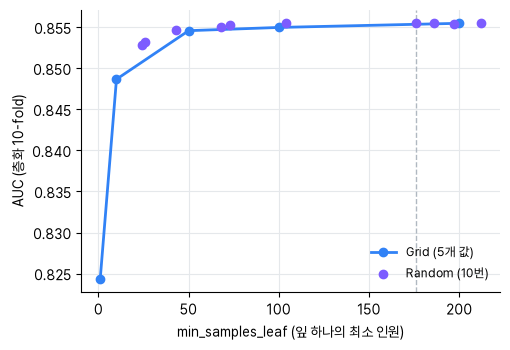

In [11]:
# 그림 1: 튜닝 곡선 (격자 + 무작위)
fig, ax = pyplot.subplots(figsize=(5.2, 3.6))
ax.plot(leaves, grid.cv_results_['mean_test_score'], '-o', color=BLUE, lw=2, label='Grid (5개 값)', zorder=3)
ra, rb = zip(*tried)
ax.scatter(ra, rb, color=VIOLET, s=36, label='Random (10번)', zorder=4)
best_leaf = rsearch.best_params_['min_samples_leaf'] if rsearch.best_score_ > grid.best_score_ else grid.best_params_['min_samples_leaf']
ax.axvline(best_leaf, color=GRAY, ls='--', lw=1)
ax.set_xlabel('min_samples_leaf (잎 하나의 최소 인원)'); ax.set_ylabel('AUC (층화 10-fold)')
ax.legend(frameon=False, fontsize=9, loc='lower right')
ax.spines[['top', 'right']].set_visible(False); ax.grid(color='#E5E8EB'); ax.set_axisbelow(True)
pyplot.tight_layout(); pyplot.savefig('../figures/lab5_tuning.png', dpi=200); pyplot.show()

## 최종 모델 비교와 저장 (Lab 5: 4. Saving and Loading Models)

In [12]:
best_leaf = int(rsearch.best_params_['min_samples_leaf'] if rsearch.best_score_ > grid.best_score_ else grid.best_params_['min_samples_leaf'])
final = Pipeline([('clean', FunctionTransformer(clean)),
                  ('rf', RandomForestClassifier(n_estimators=100, max_features=3, min_samples_leaf=best_leaf, random_state=seed, n_jobs=-1))])
r_final, _ = auc(final)
r_rf_noclean, _ = auc(RandomForestClassifier(n_estimators=100, max_features=3, min_samples_leaf=best_leaf, random_state=seed, n_jobs=-1))
print(f'최종 (정리 + RF leaf={best_leaf}): AUC {r_final.mean():.4f} ({r_final.std():.4f})  · 정리 없이 {r_rf_noclean.mean():.4f}')

최종 (정리 + RF leaf=176): AUC 0.8556 (0.0070)  · 정리 없이 0.8555


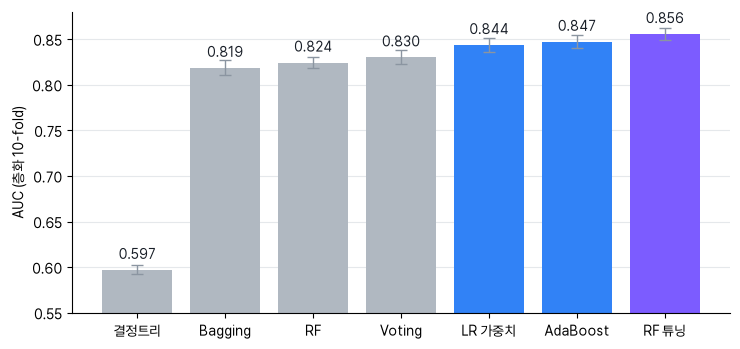

In [13]:
# 그림 2: 지금까지의 모델 AUC
r_lr = clean_rows['LR 가중치'][0]
bars = [('결정트리', ens['결정트리 1개'][0]), ('Bagging', ens['Bagging 100'][0]), ('RF', ens['RF 100'][0]),
        ('Voting', ens['Voting'][0]), ('LR 가중치', r_lr), ('AdaBoost', ens['AdaBoost 30'][0]),
        (f'RF 튜닝', r_final)]
fig, ax = pyplot.subplots(figsize=(7.5, 3.6))
cols = [GRAY] * 4 + [BLUE, BLUE, VIOLET]
ax.bar([b[0] for b in bars], [b[1].mean() for b in bars], yerr=[b[1].std() for b in bars], color=cols, capsize=4,
       error_kw={'ecolor': '#8B95A1', 'lw': 1})
for i, (_, r) in enumerate(bars):
    ax.text(i, r.mean() + 0.012, f'{r.mean():.3f}', ha='center', fontsize=10, color=INK)
ax.set_ylim(0.55, 0.88); ax.set_ylabel('AUC (층화 10-fold)')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#E5E8EB'); ax.set_axisbelow(True)
pyplot.tight_layout(); pyplot.savefig('../figures/lab5_models.png', dpi=200); pyplot.show()

In [14]:
from pickle import dump, load
import joblib
from sklearn.metrics import roc_auc_score
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.33, random_state=7, stratify=Y)
final.fit(X_train, Y_train)

dump(final, open('finalized_model.sav', 'wb'))            # pickle
joblib.dump(final, 'finalized_model1.sav')                 # joblib
# some time later...
loaded_model = load(open('finalized_model.sav', 'rb'))
loaded_model1 = joblib.load('finalized_model1.sav')
for fn, how, m in [('finalized_model.sav', 'pickle', loaded_model), ('finalized_model1.sav', 'joblib', loaded_model1)]:
    print(f'{fn} ({how}): {os.path.getsize(fn) / 1e6:.1f} MB · 시험 데이터 AUC {roc_auc_score(Y_test, m.predict_proba(X_test)[:, 1]):.4f}')
print('Python', sys.version.split()[0], '· scikit-learn', sklearn.__version__, '· numpy', numpy.__version__)

finalized_model.sav (pickle): 3.7 MB · 시험 데이터 AUC 0.8558
finalized_model1.sav (joblib): 3.7 MB · 시험 데이터 AUC 0.8558
Python 3.13.2 · scikit-learn 1.9.1 · numpy 2.5.4


**(q)(r)(s)** 저장한 모델을 다시 불러와도 시험 데이터 AUC가 같다. 저장 파일에는 정리 단계(clean)까지 들어 있어, 새 고객 데이터를 원본 그대로 넣으면 된다.
다만 불러올 때 같은 Python·scikit-learn 버전이 필요하고(위에 기록), 파이프라인 안의 `clean`, `log4` 함수도 같은 코드로 정의돼 있어야 한다.
RF는 트리 100개를 모두 저장해서 파일이 크다(로지스틱 회귀는 계수 8개).

## 정리: 발견 → 다음 질문
- 발견 1: **누수를 막아도 AUC가 같았다** (LR 가중치 0.84358 → 0.84358, LDA 0.83176 → 0.83176). 15만 건이라 fold마다 평균 차이가 표준편차의 0.1% 이하다 → Lab 2~4의 결과는 유효하다.
- 발견 2: **데이터 정리 효과는 거의 없었다.** 96/98 코드 269행은 연체율 54.6%지만 모두 '연체 이력'=1이라 이미 반영돼 있었다. 소득 대체값(29,737행)도 연체율 차이가 작다(5.6% vs 6.9%).
- 발견 3: **트리는 합치고(앙상블) 덜 외우게 하자(튜닝) 크게 올랐다.** 결정트리 0.597 → Bagging 0.819 → RF 0.824 → 잎 최소 인원 176명 RF **0.8556**. Grid(200)와 Random(176)은 0.8555로 같았고, 50명 이상에서 평평하다.
- 발견 4: 저장한 모델(3.7 MB)을 다시 불러와도 시험 AUC 0.8558로 같다.

**목표(연체 예측)에 대한 결론:** 최종 후보는 '데이터 정리 + RF(잎 최소 176명)' 파이프라인, AUC 0.856. 다음 신경망은 이 기준을 넘어야 의미가 있다.

**다음 질문 (Lab 6):** 신경망(MLP)은 15만 건에서 이 기준을 넘을 수 있을까? 그리고 15만 건을 어떻게 효율적으로 학습시킬까?